# Week 5 - Wed Lab (09/30/26) 

This code accompanies activities for the 09/30/26 lab.

**Table of Contents**

1. [Plicker Questions Code](#sec1)
2. [Cosine Similarity Whiteboard Activity - Your Task](#sec2)
3. [Wikipedia country-specific data](#sec3)

<a id="sec1"></a>
## 1. Plicker Questions Code

This code relates to the Question 13 on the Plicker set of questions for today. We will run the code line by line to see what is going on.

In [1]:
from datetime import datetime, timedelta

**Create a new datetime object**

In [2]:
date1 = datetime(2023, 5, 1)
type(date1)

datetime.datetime

**Create a new timedelta object**

In [3]:
delta = timedelta(days=10)
type(delta)

datetime.timedelta

In [4]:
print(delta)

10 days, 0:00:00


**Adding the two objects**

In [4]:
date2 = date1 + delta
print(date2)

2023-05-11 00:00:00


**Why is this possible?**

Let's show all methods / properties of the object:

In [6]:
dir(date1)

['__add__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__rsub__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 'astimezone',
 'combine',
 'ctime',
 'date',
 'day',
 'dst',
 'fold',
 'fromisocalendar',
 'fromisoformat',
 'fromordinal',
 'fromtimestamp',
 'hour',
 'isocalendar',
 'isoformat',
 'isoweekday',
 'max',
 'microsecond',
 'min',
 'minute',
 'month',
 'now',
 'replace',
 'resolution',
 'second',
 'strftime',
 'strptime',
 'time',
 'timestamp',
 'timetuple',
 'timetz',
 'today',
 'toordinal',
 'tzinfo',
 'tzname',
 'utcfromtimestamp',
 'utcnow',
 'utcoffset',
 'utctimetuple',
 'weekday',
 'year']

Let's look up the docstring of the method `__add__`, which is what is called when we use the + operator:

In [7]:
help(date1.__add__)

Help on method-wrapper:

__add__(value, /) unbound datetime.datetime method
    Return self+value.



**Conclusion:** There is a class method that will accept any value type and then act accordingly to figure out how to add that value to the date, if possible.

<a id="sec2"></a>
## 2. Cosine Similarity Whiteboard Activity

This activity was completed by hand, here is how to do it via Python code.

### Inputs for the problem

In [8]:
documents = [
    "Max likes Sam.",    # D1
    "Sam likes Max.",    # D2
    "Max and Sam.",      # D3
    "Winter likes fall." # D4
]

query = "Sam likes winter"

### Step 1: Create vocabulary of all terms

First I will concatenate all strings into one.

In [9]:
allText = " ".join(documents + [query])
print(allText)

Max likes Sam. Sam likes Max. Max and Sam. Winter likes fall. Sam likes winter


I don't want to have punctuation. There are several ways to do that. Let's see some:

#### Method 1: Iterate over the string, leave out punctuations

In [10]:
import string
print(string.punctuation)


!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [11]:
allText_noPunct = "".join([ch for ch in allText if not ch in string.punctuation])
print(allText_noPunct)

Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter


### Method 2: Use built-in methods

Pythyn's built-in `str` class has many useful methods for translating a set of characters to another one. Let's see the method in action:

In [12]:
allText.translate(str.maketrans("", "", string.punctuation))

'Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter'

What's going on?

In [13]:
print(str.maketrans("", "", string.punctuation))

{33: None, 34: None, 35: None, 36: None, 37: None, 38: None, 39: None, 40: None, 41: None, 42: None, 43: None, 44: None, 45: None, 46: None, 47: None, 58: None, 59: None, 60: None, 61: None, 62: None, 63: None, 64: None, 91: None, 92: None, 93: None, 94: None, 95: None, 96: None, 123: None, 124: None, 125: None, 126: None}


We can see that all ASCII Characters from 0-32 and from 65 to 90 are missing, because those characters will be deleted.

Here is what is happening:

```
str.maketrans(from_str, to_str, delete_chars)
#              ^          ^        ^
#           1st arg    2nd arg  3rd arg
```

* 1st argument (""): The characters you want to replace. (Empty string = replace nothing)

* 2nd argument (""): The characters to replace them with. (Empty string = no replacement mapping)

* 3rd argument (string.punctuation): The characters you want to delete entirely.

### Our vocabulary

Here is a Python one-liner that takes our variable `allText_noPunct` and find the unique words in it.

In [14]:
words = set(allText_noPunct.lower().split())
words

{'and', 'fall', 'likes', 'max', 'sam', 'winter'}

In [15]:
voc = sorted(words)
voc

['and', 'fall', 'likes', 'max', 'sam', 'winter']

### YOUR TURN

Write code to implement the other steps of the process shown in Slide 7.

**Show your process before writing any functions.**

**Use markdown to label the three remaining steps.**

### Step 2: Represent each document and the query in the vector space created by these terms

In [31]:
# convert the input into a wordlist
wordlist = [doc.lower().replace(".", "").split() for doc in documents]

# add the query to the wordlist
query_words = query.lower().replace(".", "").split()
wordlist.append(query_words)

vectors = []

for word in wordlist: 
    vec = [word.count(term) for term in voc]
    vectors.append(vec)

vectors

[[0, 0, 1, 1, 1, 0],
 [0, 0, 1, 1, 1, 0],
 [1, 0, 0, 1, 1, 0],
 [0, 1, 1, 0, 0, 1],
 [0, 0, 1, 0, 1, 1]]

In [ ]:
# convert the vector space to a dataframe
import pandas as pd

df = pd.DataFrame(vectors, columns=voc)
df.index = ["D1", "D2", "D3", "D4", "Query"]
df

,and,fall,likes,max,sam,winter
D1,0,0,1,1,1,0
D2,0,0,1,1,1,0
D3,1,0,0,1,1,0
D4,0,1,1,0,0,1
Query,0,0,1,0,1,1


### Step 3: Calculate the cosine similarity between the query and each document

In [43]:
import numpy as np
from numpy.linalg import norm
import math

# define cosineSimilarity
def cosineSimilarity(vec1, vec2): 
    v1=np.array(vec1)
    v2=np.array(vec2)
    denom = norm(v1)*norm(v2)
    return np.dot(v1, v2)/denom if denom else 0

In [ ]:
scores = []

# run cosineSimilarity on each doc with the query
for i, vec in enumerate(vectors[:4]):
    score = cosineSimilarity(vec, vectors[4])
    scores.append({
        "document": documents[i],
        "similarity score": score
    })

scores

[{'document': 'Max likes Sam.',
  'similarity score': np.float64(0.6666666666666667)},
 {'document': 'Sam likes Max.',
  'similarity score': np.float64(0.6666666666666667)},
 {'document': 'Max and Sam.',
  'similarity score': np.float64(0.33333333333333337)},
 {'document': 'Winter likes fall.',
  'similarity score': np.float64(0.6666666666666667)}]

### Step 4: Rank the results based on the cosine similarity

In [47]:
ranked_scores = sorted(scores, key=lambda x:x["similarity score"], reverse=True)
ranked_scores

[{'document': 'Max likes Sam.',
  'similarity score': np.float64(0.6666666666666667)},
 {'document': 'Sam likes Max.',
  'similarity score': np.float64(0.6666666666666667)},
 {'document': 'Winter likes fall.',
  'similarity score': np.float64(0.6666666666666667)},
 {'document': 'Max and Sam.',
  'similarity score': np.float64(0.33333333333333337)}]

<a id="sec3"></a>
## 3. Wikipedia Country-Specific Data

If we know the URL of a date, for example:

```
https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv
```

we can use pandas to read the content of the file into a dataframe. 

In [ ]:
import pandas as pd

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

df = pd.read_csv(
    url,
)

df.head()


HTTPError: HTTP Error 403: Forbidden

Why did this happen? Wikimedia didn't like that we didn't identify ourselves. This is why we need to first get data with requests, then read it from pandas.

In [88]:
import pandas as pd
import requests, io

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: yz111@wellesley.edu)'}
response = requests.get(url, headers=headers)

df = pd.read_csv(io.StringIO(response.content.decode("utf-8")), sep='\t')
df.head()

,Algeria,DZ,ar.wikipedia,3947,ذكاء_اصطناعي,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,José_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


The dataframe doesn't have column name. 

**Your task:** Read the README file to find out the column names and add them to the dataframe.


In [89]:
df.columns = ["country", "country_code", "wiki", "page_id", "article", "qid", "views"]

In [90]:
df.head()

,country,country_code,wiki,page_id,article,qid,views
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,José_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


In [ ]:
# select shows
top_shows = ["Dream_to_You", 
             "A_Love_Other_Than_Yours", 
             "Four_Hands,_Two_Sonatas", 
             "Flex_X_Cop", 
             "Our_Sticky_Love", 
             "My_Bias,_My_Boss", 
             "A_Bona_Fide_Killer", 
             "The_Affair_Was_Just_the_Beginning", 
             "A_Shop_for_Killers", 
             "Spooky_in_Love"]

In [91]:
df_sep = []

for day in range(1, 31):
    url = f"https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-{day:02d}.tsv"
    headers = { "User-Agent": "MyDataAnalysisScript/1.0 (contact: yz111@wellesley.edu)"}
    response = requests.get(url, headers=headers)
    daily_df = pd.read_csv(io.StringIO(response.content.decode("utf-8")),sep="\t",header=None)
    daily_df.columns = ["country", "country_code", "wiki", "page_id", "article", "qid", "views"]
    daily_df["date"] = f"2026-09-{day:02d}"
    df_sep.append(daily_df)

df_sep = pd.concat(df_sep, ignore_index=True)

# Check df_sep
df_sep.head()

KeyboardInterrupt: 

In [ ]:
pageviews = []

for show in top_shows: 
    filtered_df = df_sep[df_sep["article"] == show]
    pageviews.append({
        "show": show, 
        "pageviews in Sep 2026": sum(filtered_df["views"])
    })

In [ ]:
# save it to a csv file
df_pageviews = pd.DataFrame(pageviews)
df_pageviews.to_csv("pageviews.csv")

In [ ]:
pv_by_countries = []

for show in top_shows: 
    filtered_df = df_sep[df_sep["article"] == show]
    for show, show_df in filtered_df.groupby("article"): 
        for country, country_df in show_df.groupby("country"):
            pv_by_countries.append({
                "show": show, 
                "country": country, 
                "pageviews": country_df["views"].sum()
            })

pv_by_countries

[{'show': 'Dream_to_You', 'country': 'India', 'pageviews': np.int64(3894)},
 {'show': 'Dream_to_You', 'country': 'Malaysia', 'pageviews': np.int64(93)},
 {'show': 'Dream_to_You',
  'country': 'Philippines',
  'pageviews': np.int64(604)},
 {'show': 'Dream_to_You', 'country': 'Singapore', 'pageviews': np.int64(181)},
 {'show': 'Dream_to_You',
  'country': 'United States',
  'pageviews': np.int64(3665)},
 {'show': 'A_Love_Other_Than_Yours',
  'country': 'Argentina',
  'pageviews': np.int64(841)},
 {'show': 'A_Love_Other_Than_Yours',
  'country': 'Belgium',
  'pageviews': np.int64(98)},
 {'show': 'A_Love_Other_Than_Yours',
  'country': 'Brazil',
  'pageviews': np.int64(2651)},
 {'show': 'A_Love_Other_Than_Yours',
  'country': 'Canada',
  'pageviews': np.int64(5506)},
 {'show': 'A_Love_Other_Than_Yours',
  'country': 'Chile',
  'pageviews': np.int64(731)},
 {'show': 'A_Love_Other_Than_Yours',
  'country': 'Colombia',
  'pageviews': np.int64(553)},
 {'show': 'A_Love_Other_Than_Yours',
  'cou

In [87]:
df_pv_by_countries = pd.DataFrame(pv_by_countries)
df_pv_by_countries.to_csv("pageviews_by_countries.csv")

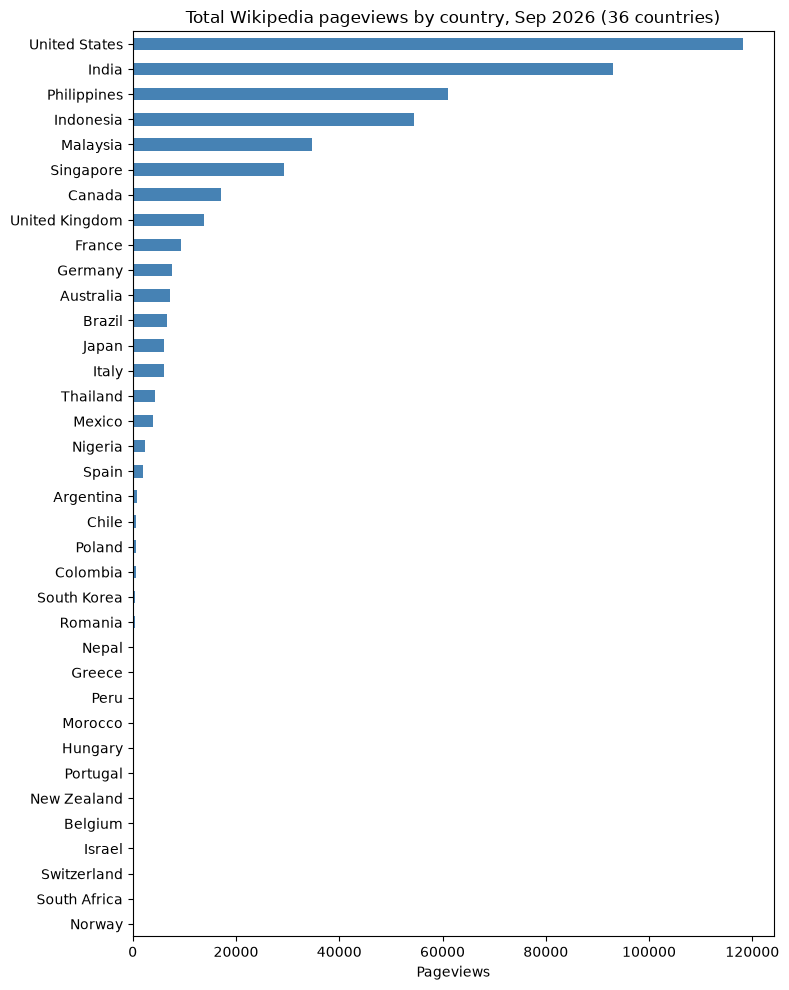

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Bar chart: total views by country
views_by_country = df_pv_by_countries.groupby("country")["pageviews"].sum().sort_values()
ax = views_by_country.plot(kind="barh", figsize=(8, 10), color="steelblue")
ax.set_title(f"Total Wikipedia pageviews by country, Sep 2026 ({len(views_by_country)} countries)")
ax.set_xlabel("Pageviews")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

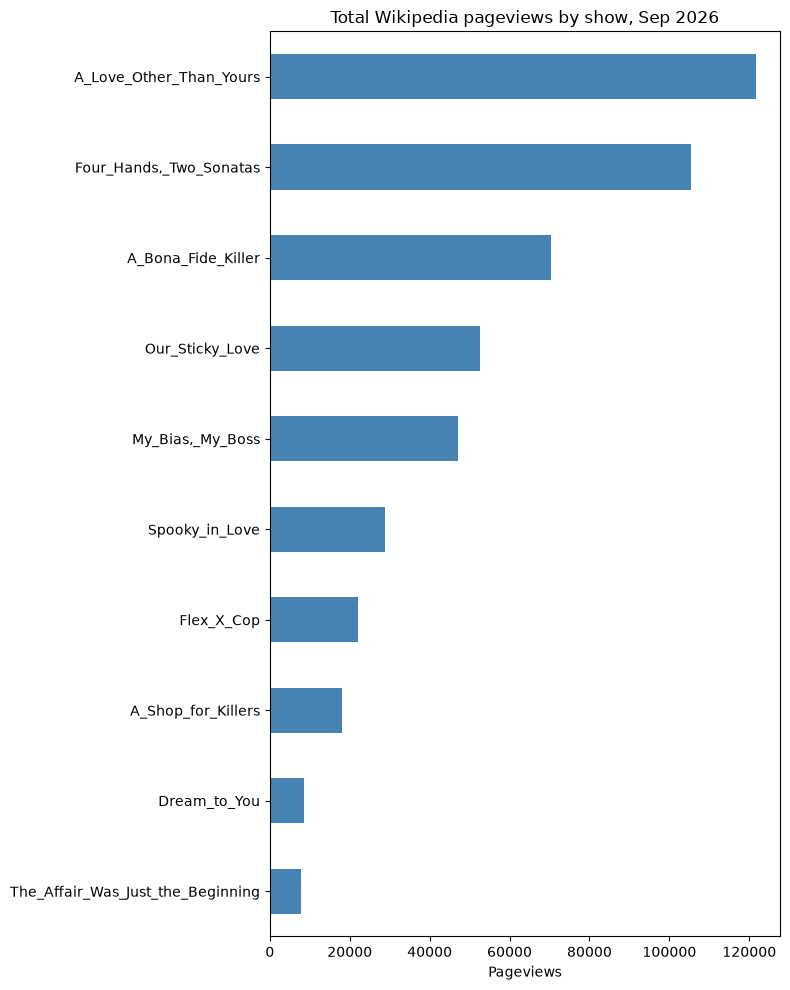

In [15]:
# Bar chart: Total views by show
views_by_show = df_pv_by_countries.groupby("show")["pageviews"].sum().sort_values()
ax = views_by_show.plot(kind="barh", figsize=(8, 10), color="steelblue")
ax.set_title(f"Total Wikipedia pageviews by show, Sep 2026")
ax.set_xlabel("Pageviews")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

#### Does the popularity in Wikipedia pageviews correlate to the rating for the shows in MyDramaList? 

Based on the limited sample selected for this study, Wikipedia pageviews do not appear to correlate closely with show ratings on MyDramaList. Among the ten selected shows, *A Love Other Than Yours* has the lowest rating at 7.6, while *Four Hands, Two Sonatas* has the highest rating at 8.7. Despite this substantial difference in ratings, the two shows received relatively similar numbers of Wikipedia pageviews. Likewise, *Flex X Cop* (rated 8.3) and *Our Sticky Love* (rated 8.2) have nearly identical ratings, yet their pageview counts differ considerably, with *Flex X Cop* receiving only about half as many pageviews as *Our Sticky Love*. These examples suggest that, within this sample, higher ratings are not necessarily associated with greater Wikipedia traffic. Other factors beyond ratings, such as popularity, cast recognition, international exposure, or promotional activity, may also play a role in shaping pageview patterns. 